<a href="https://colab.research.google.com/github/Samarbal/Deep-Learning-/blob/main/Introduction_to_Recurrent_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introduction to Recurrent Neural Networks

Samar Mohammed Balousha

2320222601

A Recurrent Neural Network is a type of neural network designed to process sequential data—that is, data in which the order of the elements is important.
- Text
- Time Series
- Speech

In [4]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Task 1: Vocabulary and One-Hot Encoding

In [5]:
# 1. expand the vocabulary
vocabulary = ['Neural', 'Networks', 'Process', 'Deep', 'Learning']

print("Vocabulary:", vocabulary)
print("Vocabulary Size:", len(vocabulary))

Vocabulary: ['Neural', 'Networks', 'Process', 'Deep', 'Learning']
Vocabulary Size: 5


In [6]:
# 2. mapping and encoding : Word-to-Index Mapping
word_to_index = {word: index for index, word in enumerate(vocabulary)}
print("Word-to-Index Mapping:", word_to_index)


Word-to-Index Mapping: {'Neural': 0, 'Networks': 1, 'Process': 2, 'Deep': 3, 'Learning': 4}


In [7]:
# 4th index - one hot vector
fourth_word = vocabulary[3]
word_index = word_to_index[fourth_word]

one_hot_vector = tf.one_hot(
    word_index,
    depth=len(vocabulary)
)

print("Fourth Word:", fourth_word)
print("Word Index:", word_index)
print("One-Hot Vector:", one_hot_vector.numpy())

Fourth Word: Deep
Word Index: 3
One-Hot Vector: [0. 0. 0. 1. 0.]


3. **Question**: Print the index and the resulting One-Hot vector. What happens to the size of the One-Hot vector if your vocabulary grows to 10,000 words?

**Answer**:

- If the vocabulary grows to 10000 words, each One-Hot vector will contain 10000 elements.
- Only one element will be 1, while the remaining 9999 elements will be 0, resulting in a high-dimensional sparse representation.


### Task2: Mnaual SimpleRNNCell Exploration

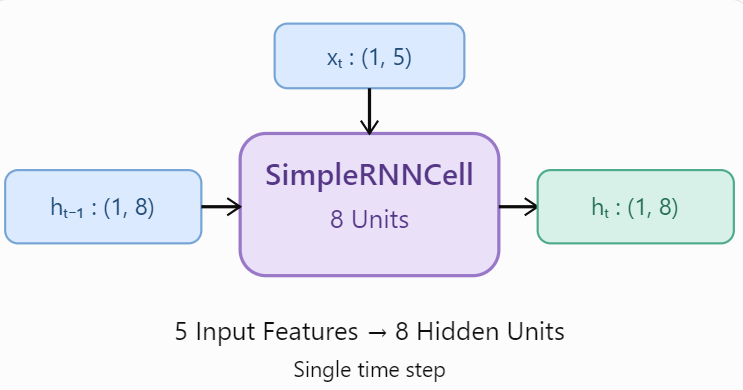

In [8]:
# 1. Initialize SimpleRNNCell
rnn_cell = layers.SimpleRNNCell(units=8)  # the cell has 8 hidden units

# 2. Create input vector
xt = tf.random.normal([1, 5])  # batch size = 1 , inout features = 5

# 3. Initialize hidden state
ht_minus_1 = tf.zeros([1, 8]) # all the values are zeros for all the hidden layers

# 4.Pass input through the cell
output, next_hidden_state = rnn_cell(
    xt,  # input
    [ht_minus_1]  # hidden state list
)

#  here the rnn cell would return the - output of the current step , and next_hidden_state which is the tensor for the next hidden states


In [9]:
# 5. Print the shapes and values of the output and the next hidden state.
print("Output Shape:", output.shape)
print("Output Values:", output.numpy())
print("--------------------------------------")
print("Next Hidden State Shape:", next_hidden_state[0].shape)
print("Next Hidden State Values:", next_hidden_state[0].numpy())


Output Shape: (1, 8)
Output Values: [[-0.77867466 -0.30526587  0.3400061   0.8860197   0.66407603 -0.6506891
  -0.76473355 -0.20503525]]
--------------------------------------
Next Hidden State Shape: (1, 8)
Next Hidden State Values: [[-0.77867466 -0.30526587  0.3400061   0.8860197   0.66407603 -0.6506891
  -0.76473355 -0.20503525]]


**Question**: Why does the dimension of the next hidden state match the number of units (8 units) specified in the cell?

**Answer**: because the SimpleRNNCell has 8 units, it produces 8 hidden features for each input sample, resulting in a shape of (1, 8)

### Task 3: Building Sequential RNN Models (return_sequences)

In [10]:
layers.SimpleRNN(units=64)

<SimpleRNN name=simple_rnn, built=False>

In [11]:
# 1. model A (Single Output)
model_a = tf.keras.Sequential([
    layers.Input(shape=(8, 12)), # 8 time steps (words), 12 features
    layers.SimpleRNN(units=64 , return_sequences=False),   # 64 hidden units
     # by default
])

# generate sample input
sample_input = tf.random.normal([1, 8, 12]) # batch =1, 8 words , 12 featuers for each word

# print the predection output
prediction_a = model_a.predict(sample_input)
print("Prediction Shape:", prediction_a.shape)
print("Prediction Values:", prediction_a)
print("--------------------------------------")
print(model_a.summary())

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 729ms/step
Prediction Shape: (1, 64)
Prediction Values: [[ 0.67630297  0.46407247  0.20068912  0.43363374 -0.72221696 -0.6669915
  -0.5595256   0.75149596 -0.67846704 -0.38607726  0.6919781   0.15304446
  -0.06876328 -0.10128734 -0.2661153   0.2018267  -0.5921871  -0.0720804
   0.17715605  0.30221164 -0.5477696  -0.7371205   0.99442095 -0.7753651
   0.8652664  -0.40883002 -0.40966666  0.49045557 -0.46125966  0.43130407
  -0.57147455  0.5400405  -0.64454764  0.22828011 -0.23256737 -0.86025554
  -0.64294827 -0.30724773 -0.512204   -0.2243561   0.8792617  -0.8509143
  -0.8345534  -0.5514082   0.913124   -0.80302334 -0.6068345   0.6756804
  -0.54280174 -0.3649669  -0.49797496 -0.44138697 -0.8349529   0.764526
   0.56025064 -0.5134897  -0.7533572   0.13110256  0.69060045 -0.9224625
  -0.39796293 -0.15096544  0.07452814 -0.22336277]]
--------------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         4,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,928 (19.25 KB)

 Trainable params: 4,928 (19.25 KB)

 Non-trainable params: 0 (0.00 B)

None


In [14]:
# 2. Model B — Sequence Outputs
model_b = tf.keras.Sequential([
    layers.Input(shape=(8, 12)), # 8 time steps (words), 12 features
    layers.SimpleRNN(units=64 , return_sequences=True),   # 64 hidden units
])

prediction_b = model_b(sample_input)

print("Model B Output Shape:", prediction_b.shape)
print("Prediction Values:", prediction_b)
print("--------------------------------------")
print(model_b.summary())


Model B Output Shape: (1, 8, 64)
Prediction Values: tf.Tensor(
[[[ 7.60346770e-01  8.69541228e-01  5.43367743e-01 -8.59344542e-01
   -9.31910276e-01 -3.39410976e-02  3.55813652e-01 -1.24324359e-01
    3.95609915e-01 -3.91463310e-01  8.11682522e-01  3.88612688e-01
   -7.37937093e-01  3.13866913e-01 -2.62467731e-02 -3.79081577e-01
   -3.01217854e-01 -3.29501808e-01 -8.01267624e-01 -5.56933582e-01
    2.01968446e-01  4.34444189e-01 -4.26623911e-01  4.32276100e-01
   -5.66177011e-01 -8.71979713e-01 -5.25367320e-01  2.22024888e-01
   -8.93340945e-01  4.40954983e-01 -7.70778298e-01 -9.18937325e-01
    4.70481694e-01  8.44003558e-01 -8.81348491e-01 -1.24860883e-01
    5.43390453e-01 -3.20103854e-01 -8.21931124e-01  8.67377758e-01
   -8.37750316e-01  2.58626938e-01 -8.02492440e-01 -7.85684288e-01
   -5.99714994e-01  4.23484445e-01 -4.68558446e-02  7.46019244e-01
   -3.43725681e-01 -5.49302101e-01 -1.54468775e-01 -3.58941406e-01
   -1.62200391e-01  1.86595991e-01  5.04194498e-01  4.71953779e-01

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_4 (SimpleRNN)        │ (None, 8, 64)          │         4,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,928 (19.25 KB)

 Trainable params: 4,928 (19.25 KB)

 Non-trainable params: 0 (0.00 B)

None



**Question**: Explain in 1–2 sentences the structural difference in the output tensor shape between Model A and Model B, and mention a practical use case for each.

**Answer**:
- **Model A** (return_sequences=False) returns only the final hidden state with shape (1, 64), making it suitable for sentence-level tasks : sentiment analysis, spam detection, language identification .

- **Model B** (return_sequences=True) returns the hidden state at every time step with shape (1, 8, 64), making it suitable for sequence-labeling tasks: part-of-speech tagging, weather forecasting.

![image.png](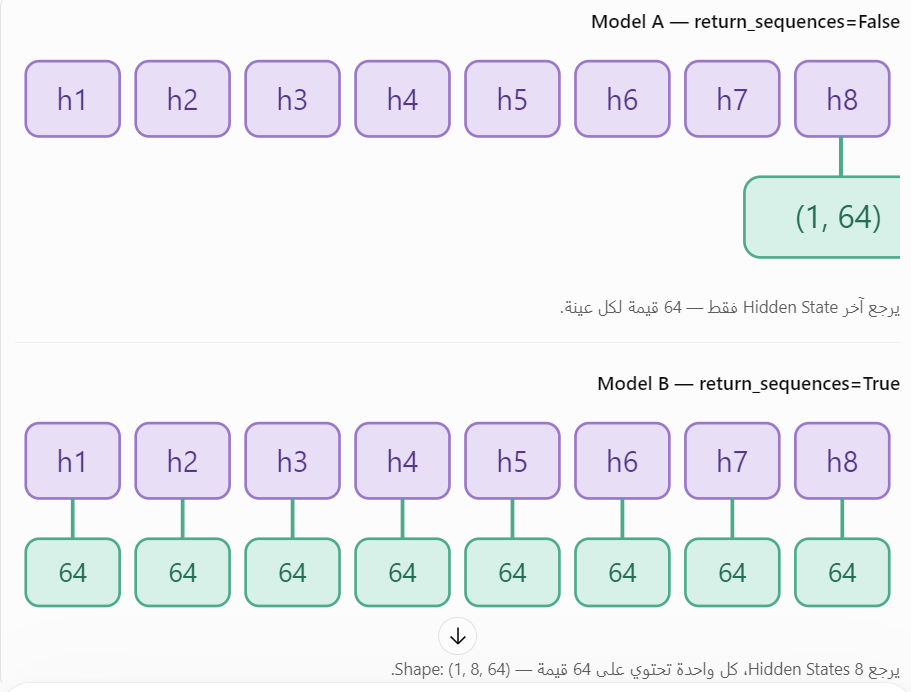)

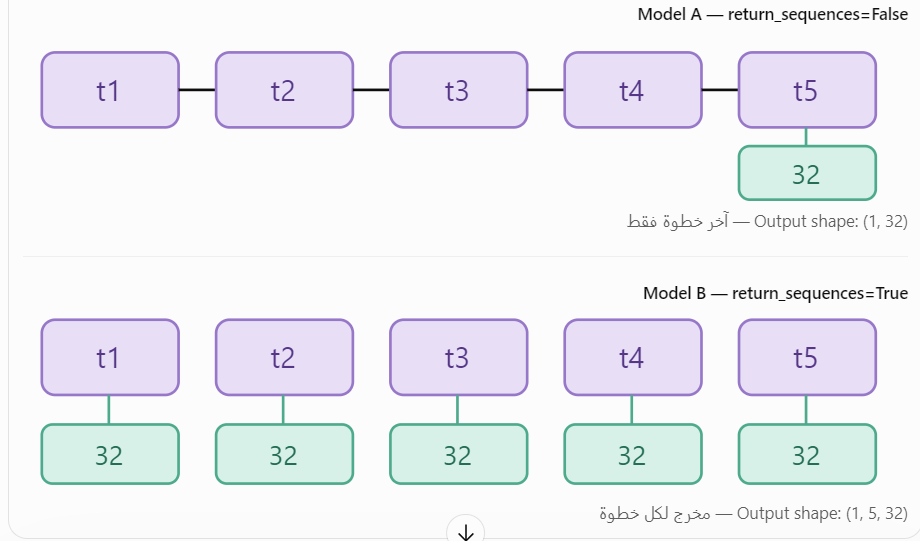

- `SimpleRNNCell` processes one time step at a time, and the input shape : `(batch, features)`




- `SimpleRNN` processes an entire sequence automatically, using a recurrent cell internally, and the inout shape : `(batch, time_steps, features)`